In [21]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT=Path.cwd().parent

sys.path.append(
    str(PROJECT_ROOT/"src")
)

In [9]:
import importlib
import data_loader
importlib.reload(data_loader)
from data_loader import load_dataset,decode_datetimes,remove_faulty_channels,create_binary_label

In [10]:
DATA_PATH=r"C:/Users/urvi_/Downloads/dataset.h5"

In [11]:
X,y_distance_raw,datetimes_raw,ship_info=load_dataset(DATA_PATH)

In [12]:
print("X shape:",X.shape)
print("Distance shape:",y_distance_raw.shape)
print("Number of timestamps:",len(datetimes_raw))
print("Ship information fields:",ship_info.keys())

X shape: (74771, 250, 100)
Distance shape: (74771,)
Number of timestamps: 74771
Ship information fields: dict_keys(['beam', 'length', 'type'])


**Remove Faulty Channels**

In [13]:
X_clean,good_channels=remove_faulty_channels(X)
print("original Shape: ",X.shape)
print("Clean Shape: ",X_clean.shape)
print("Number of good channels: ",len(good_channels))

original Shape:  (74771, 250, 100)
Clean Shape:  (74771, 247, 100)
Number of good channels:  247


**Create Labels**

In [14]:
y_binary=create_binary_label(y_distance_raw, threshold=1000)

In [16]:
print("Far:",np.sum(y_binary==0))
print("Near: ",np.sum(y_binary==1))


Far: 50521
Near:  24250


In [17]:
datetimes=decode_datetimes(datetimes_raw)
print(datetimes[:10])

DatetimeIndex(['2023-06-16 02:00:08+00:00', '2023-06-16 02:00:18+00:00',
               '2023-06-16 02:00:28+00:00', '2023-06-16 02:00:38+00:00',
               '2023-06-16 02:00:48+00:00', '2023-06-16 02:00:58+00:00',
               '2023-06-16 02:01:08+00:00', '2023-06-16 02:01:18+00:00',
               '2023-06-16 02:01:28+00:00', '2023-06-16 02:01:38+00:00'],
              dtype='datetime64[us, UTC]', freq=None)


In [20]:
days=datetimes.date
unique_days=sorted(pd.Series(days).dropna().unique())

print("Number of days: ",len(unique_days))

for day in unique_days:
    count=np.sum(days==day)
    print(day,count)

Number of days:  10
2023-06-16 7898
2023-06-17 8616
2023-06-18 8616
2023-06-19 8616
2023-06-20 8616
2023-06-21 7577
2023-06-22 2464
2023-06-23 8616
2023-06-24 8616
2023-06-25 5136


**EDA**

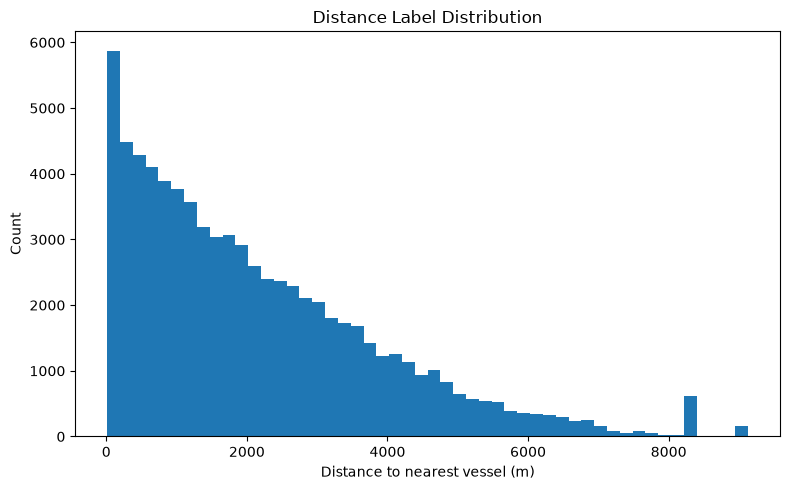

In [24]:
plt.figure(figsize=(8,5))
plt.hist(y_distance_raw,bins=50)
plt.xlabel("Distance to nearest vessel (m)")
plt.ylabel("Count")
plt.title("Distance Label Distribution")
plt.tight_layout()
plt.savefig(PROJECT_ROOT/"results"/"figures"/"distance_distribution.png",dpi=300)
plt.show()

**Binary Class Distribution**

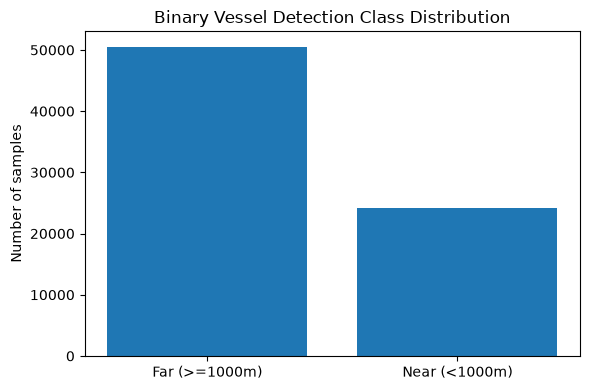

In [25]:
far_count=np.sum(y_binary==0)
near_count=np.sum(y_binary==1)
plt.figure(figsize=(6,4))
plt.bar([
    "Far (>=1000m)",
    "Near (<1000m)"
],
        [
            far_count,
            near_count
        ])
plt.ylabel("Number of samples")

plt.title("Binary Vessel Detection Class Distribution")
plt.tight_layout()
plt.savefig(PROJECT_ROOT/"results"/"figures"/"class_distribution.png",dpi=300)
plt.show()

**Vessel types**

In [28]:
types_raw=ship_info["type"]
types=[
    value.decode()
    if isinstance(value,bytes)
    else str(value)
    
    for value in types_raw
]
types=[t.strip().lower() for t in types]
type_counts=(pd.Series(types).value_counts())

print(type_counts)

hopper dredger                  13382
container ship                  11503
chemical/oil products tanker    10577
ro-ro cargo ship                 9656
general cargo ship               5661
vehicles carrier                 4922
bulk carrier                     4457
fishing vessel                   2690
unknown                          2536
lpg tanker                       2356
military ops                      752
oil products tanker               699
crude oil tanker                  590
passenger (cruise) ship           572
refrigerated cargo ship           564
lng tanker                        519
tug                               466
bunkering tanker                  394
utility vessel                    347
other type                        311
bitumen tanker                    289
patrol vessel                     288
cargo ship                        248
research vessel                   247
law enforcment                    184
liquefied gas                     182
pilot vessel

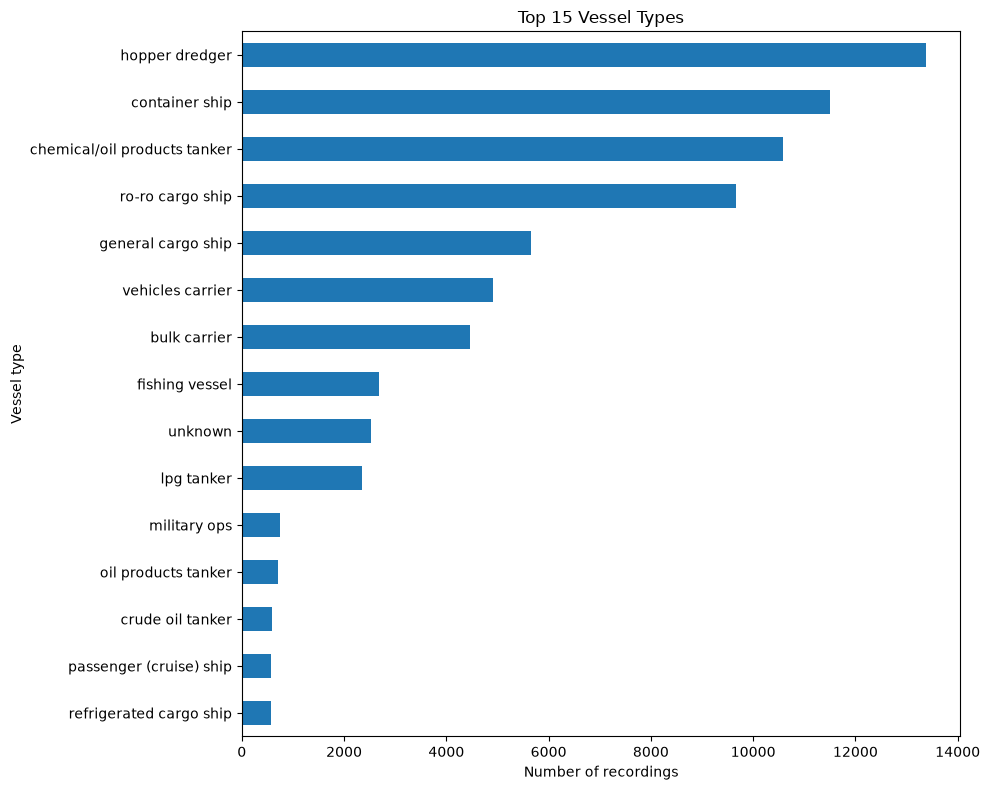

In [30]:
plt.figure(figsize=(10,8))
type_counts.head(15).sort_values().plot(kind="barh")
plt.xlabel("Number of recordings")
plt.ylabel("Vessel type")

plt.title("Top 15 Vessel Types")
plt.tight_layout()
plt.savefig(PROJECT_ROOT/"results"/"figures"/"vessel_types.png",dpi=300)
plt.show()